Dataset Link: https://www.kaggle.com/datasets/puneet6060/intel-image-classification?utm_source=chatgpt.com

In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive (1).zip to archive (1).zip


In [2]:
import zipfile
import os

zip_path = "archive (1).zip"
extract_path = "/content/intel_dataset"

print("Extracting dataset...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

# Inspect extracted folders
for root, dirs, files_list in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

Extracting dataset...
Extraction completed!
intel_dataset/
  seg_train/
    seg_train/
  seg_test/
    seg_test/
  seg_pred/
    seg_pred/


In [3]:
import os

train_dir = "/content/intel_dataset/seg_train/seg_train"
test_dir = "/content/intel_dataset/seg_test/seg_test"

print("Training classes:")
for cls in sorted(os.listdir(train_dir)):
    path = os.path.join(train_dir, cls)
    if os.path.isdir(path):
        print(f"{cls}: {len(os.listdir(path))} images")

print("\nTesting classes:")
for cls in sorted(os.listdir(test_dir)):
    path = os.path.join(test_dir, cls)
    if os.path.isdir(path):
        print(f"{cls}: {len(os.listdir(path))} images")

Training classes:
buildings: 2191 images
forest: 2271 images
glacier: 2404 images
mountain: 2512 images
sea: 2274 images
street: 2382 images

Testing classes:
buildings: 437 images
forest: 474 images
glacier: 553 images
mountain: 525 images
sea: 510 images
street: 501 images


In [4]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import random
from collections import Counter

# Reproducibility
random.seed(42)
torch.manual_seed(42)

classes_to_use = [
    "buildings", "forest", "glacier", "mountain", "sea"
]

# Image preprocessing
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load datasets
full_train = datasets.ImageFolder(train_dir, transform=transform)
full_test = datasets.ImageFolder(test_dir, transform=transform)

print("Class mapping:", full_train.class_to_idx)

# Select balanced indices
def get_balanced_indices(dataset, selected_classes, samples_per_class):
    indices = []

    for class_name in selected_classes:
        class_idx = dataset.class_to_idx[class_name]

        class_indices = [
            i for i, (_, label) in enumerate(dataset.samples)
            if label == class_idx
        ]

        selected = random.sample(class_indices, samples_per_class)
        indices.extend(selected)

    random.shuffle(indices)
    return indices

train_indices = get_balanced_indices(full_train, classes_to_use, 1000)
test_indices = get_balanced_indices(full_test, classes_to_use, 200)

train_dataset = Subset(full_train, train_indices)
test_dataset = Subset(full_test, test_indices)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False, num_workers=2
)

print("\nTraining images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Classes:", classes_to_use)

Class mapping: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}

Training images: 5000
Testing images: 1000
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea']


In [7]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("CUDA available:", torch.cuda.is_available())
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
Selected device: cuda
GPU: Tesla T4


In [8]:
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


cnn_model = SimpleCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

print(cnn_model)
print("Model device:", next(cnn_model.parameters()).device)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=5, bias=True)
  )
)
Model device: cuda:0


In [9]:
def train_model(model, loader, optimizer, criterion, epochs=5):
    model.to(device)

    for epoch in range(epochs):
        model.train()
        running_loss = 0
        correct = 0
        total = 0

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        epoch_loss = running_loss / total
        accuracy = 100 * correct / total

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Accuracy: {accuracy:.2f}%"
        )

    return model


cnn_model = train_model(
    cnn_model,
    train_loader,
    optimizer,
    criterion,
    epochs=5
)

Epoch [1/5] Loss: 1.0129 Accuracy: 59.58%
Epoch [2/5] Loss: 0.7552 Accuracy: 71.04%
Epoch [3/5] Loss: 0.6300 Accuracy: 76.50%
Epoch [4/5] Loss: 0.5235 Accuracy: 80.80%
Epoch [5/5] Loss: 0.4183 Accuracy: 84.88%


In [10]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

def evaluate_model(model, loader):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)

    print(f"Test Accuracy: {accuracy * 100:.2f}%")
    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=classes_to_use
    ))

    return y_true, y_pred


cnn_y_true, cnn_y_pred = evaluate_model(cnn_model, test_loader)

cnn_cm = confusion_matrix(cnn_y_true, cnn_y_pred, labels=[0, 1, 2, 3, 4])
print("Confusion Matrix:\n", cnn_cm)

Test Accuracy: 79.40%

Classification Report:
              precision    recall  f1-score   support

   buildings       0.76      0.92      0.83       200
      forest       0.94      0.94      0.94       200
     glacier       0.85      0.67      0.75       200
    mountain       0.86      0.56      0.68       200
         sea       0.66      0.89      0.76       200

    accuracy                           0.79      1000
   macro avg       0.81      0.79      0.79      1000
weighted avg       0.81      0.79      0.79      1000

Confusion Matrix:
 [[183  10   0   1   6]
 [ 12 187   0   0   1]
 [ 11   0 134  13  42]
 [ 23   0  21 112  44]
 [ 13   2   3   4 178]]


Pretrained ResNet18

In [11]:
from torchvision import models
import torch.nn as nn

# Load pretrained ResNet18
resnet_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze all existing layers
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace final layer for our 5 classes
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    5
)

# Move model to GPU
resnet_model = resnet_model.to(device)

# Loss and optimizer (train only the new final layer)
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    resnet_model.fc.parameters(),
    lr=0.001
)

print("ResNet18 loaded successfully!")
print("Trainable parameters:",
      sum(p.numel() for p in resnet_model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 108MB/s]

ResNet18 loaded successfully!
Trainable parameters: 2565


In [12]:
resnet_model = train_model(
    resnet_model,
    train_loader,
    optimizer,
    criterion,
    epochs=5
)

Epoch [1/5] Loss: 0.8118 Accuracy: 71.62%
Epoch [2/5] Loss: 0.4254 Accuracy: 86.40%
Epoch [3/5] Loss: 0.3601 Accuracy: 87.68%
Epoch [4/5] Loss: 0.3387 Accuracy: 88.02%
Epoch [5/5] Loss: 0.3119 Accuracy: 89.26%


In [13]:
resnet_y_true, resnet_y_pred = evaluate_model(
    resnet_model,
    test_loader
)

resnet_cm = confusion_matrix(
    resnet_y_true,
    resnet_y_pred,
    labels=[0, 1, 2, 3, 4]
)

print("Confusion Matrix:\n", resnet_cm)

Test Accuracy: 88.20%

Classification Report:
              precision    recall  f1-score   support

   buildings       1.00      1.00      1.00       200
      forest       0.98      0.97      0.98       200
     glacier       0.80      0.79      0.79       200
    mountain       0.79      0.71      0.75       200
         sea       0.83      0.93      0.88       200

    accuracy                           0.88      1000
   macro avg       0.88      0.88      0.88      1000
weighted avg       0.88      0.88      0.88      1000

Confusion Matrix:
 [[200   0   0   0   0]
 [  0 195   3   1   1]
 [  0   2 158  26  14]
 [  0   1  33 143  23]
 [  0   0   4  10 186]]


Observations:
- ResNet18 performs better overall.
- Buildings: ResNet18 achieved 100% recall.
- Forest: ResNet18 achieved 97% recall.
- Glacier and mountain remain challenging.
- Glacier and mountain are frequently confused in both models.

Fine-tune ResNet18


we'll unfreeze the last convolutional block (layer4)

In [14]:
# Unfreeze the last ResNet block
for param in resnet_model.layer4.parameters():
    param.requires_grad = True

# Keep earlier layers frozen
for param in resnet_model.parameters():
    if not any(param is p for p in resnet_model.layer4.parameters()) \
       and not any(param is p for p in resnet_model.fc.parameters()):
        param.requires_grad = False

# Use smaller learning rate for fine-tuning
optimizer = torch.optim.Adam([
    {"params": resnet_model.layer4.parameters(), "lr": 0.0001},
    {"params": resnet_model.fc.parameters(), "lr": 0.001}
])

print("Trainable parameters:",
      sum(p.numel() for p in resnet_model.parameters() if p.requires_grad))

Trainable parameters: 8396293


In [15]:
resnet_model = train_model(
    resnet_model,
    train_loader,
    optimizer,
    criterion,
    epochs=5
)

Epoch [1/5] Loss: 0.2678 Accuracy: 90.84%
Epoch [2/5] Loss: 0.0534 Accuracy: 98.64%
Epoch [3/5] Loss: 0.0183 Accuracy: 99.58%
Epoch [4/5] Loss: 0.0091 Accuracy: 99.92%
Epoch [5/5] Loss: 0.0221 Accuracy: 99.40%


testing unlocked layer -4

In [16]:
ft_y_true, ft_y_pred = evaluate_model(
    resnet_model,
    test_loader
)

ft_cm = confusion_matrix(
    ft_y_true,
    ft_y_pred,
    labels=[0, 1, 2, 3, 4]
)

print("Fine-tuned Confusion Matrix:\n", ft_cm)

Test Accuracy: 92.80%

Classification Report:
              precision    recall  f1-score   support

   buildings       1.00      1.00      1.00       200
      forest       0.99      0.99      0.99       200
     glacier       0.83      0.87      0.85       200
    mountain       0.88      0.82      0.85       200
         sea       0.95      0.96      0.95       200

    accuracy                           0.93      1000
   macro avg       0.93      0.93      0.93      1000
weighted avg       0.93      0.93      0.93      1000

Fine-tuned Confusion Matrix:
 [[200   0   0   0   0]
 [  0 198   1   1   0]
 [  0   1 174  18   7]
 [  0   1  31 164   4]
 [  1   1   3   3 192]]


Final model comparison

92.80% Fine-tuned ResNet18 test accuracy

Model	Test accuracy

Scratch CNN	79.40%

Frozen ResNet18	88.20%

Fine-tuned ResNet18	92.80%

Inspect five misclassified images

Total misclassified images: 72


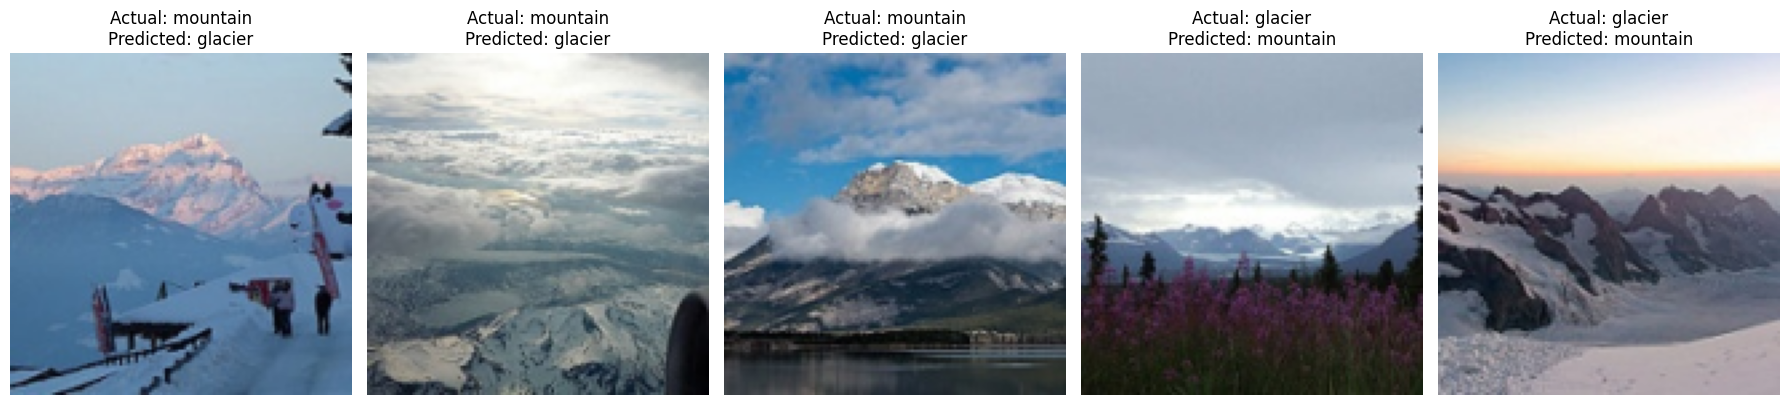

In [17]:
import matplotlib.pyplot as plt
import numpy as np

resnet_model.eval()

wrong_images = []
wrong_labels = []
wrong_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = resnet_model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu()

        for i in range(len(labels)):
            if predictions[i] != labels[i]:
                wrong_images.append(images[i].cpu())
                wrong_labels.append(labels[i].item())
                wrong_predictions.append(predictions[i].item())

print("Total misclassified images:", len(wrong_images))

# Display five misclassified images
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for i in range(min(5, len(wrong_images))):
    img = wrong_images[i].permute(1, 2, 0).numpy()
    img = np.clip(img * std + mean, 0, 1)

    true_label = classes_to_use[wrong_labels[i]]
    predicted_label = classes_to_use[wrong_predictions[i]]

    axes[i].imshow(img)
    axes[i].set_title(
        f"Actual: {true_label}\nPredicted: {predicted_label}"
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()

### Misclassified Image Analysis

I inspected five misclassified images from the fine-tuned ResNet18 model.

**Observations:**
- Three mountain images were predicted as glacier.
- Two glacier images were predicted as mountain.
- Both categories contain similar visual features, such as snow-covered peaks, rocky surfaces and white landscapes.
- Differences in lighting, clouds and background also make classification difficult.

**Conclusion:**

The model finds it difficult to distinguish glaciers from mountains because their visual characteristics overlap. This suggests that more diverse training images and clearer distinguishing features could improve classification performance.

## Final Conclusion

In this assignment, I trained and compared a CNN from scratch with a pretrained ResNet18 model for classifying five landscape categories: buildings, forest, glacier, mountain and sea.

### Model Comparison

| Model | Test Accuracy |
|---|---:|
| CNN from Scratch | 79.40% |
| ResNet18 (Frozen Layers) | 88.20% |
| ResNet18 (Fine-tuned) | 92.80% |

### Key Learnings

- A CNN can learn image features such as edges, textures and shapes from training data.
- ResNet18 performed better because its pretrained layers already learned useful visual features from ImageNet.
- Fine-tuning the last convolutional block helped the model adapt those features to the landscape dataset.
- Glacier and mountain images were the most commonly confused categories because of their similar visual characteristics.

### Final Result

Fine-tuned ResNet18 achieved the highest test accuracy of 92.80%, outperforming the CNN trained from scratch by 13.40 percentage points.

This experiment demonstrated the benefits of transfer learning and fine-tuning for image classification.